          BREAST CANCER WISCONSIN - MACHINE LEARNING

INFORMACION DEL DATASET
Total de registros: 569
Caracteristicas utilizadas: 5
Categorias: ['malignant' 'benign']

DIVISION DE LOS DATOS
Registros de entrenamiento: 455
Registros de prueba: 114

Entrenando el modelo...
Modelo entrenado correctamente.

                 EVALUACION DEL MODELO
Accuracy:  92.11%
Precision: 94.37%
Recall:    93.06%
F1-Score:  93.71%

REPORTE DE CLASIFICACION
              precision    recall  f1-score   support

   malignant       0.88      0.90      0.89        42
      benign       0.94      0.93      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114


MATRIZ DE CONFUSION
[[38  4]
 [ 5 67]]


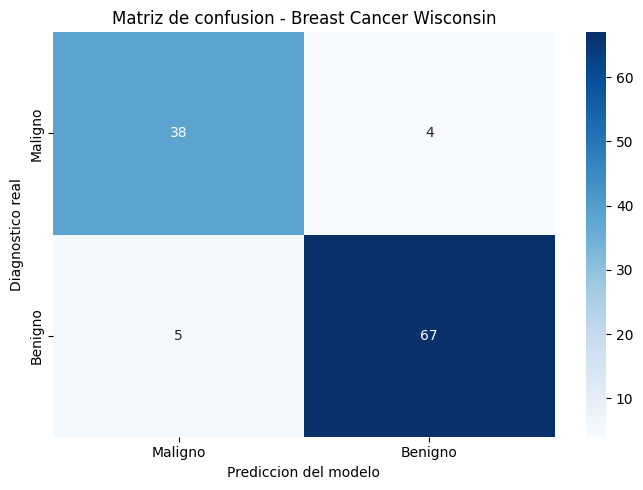


                  MENU PRINCIPAL
1. Realizar una prediccion mediante cinco medidas
2. Mostrar caracteristicas de un registro
3. Mostrar informacion de las categorias
4. Salir

Selecciona una opcion: 1

             INGRESO DE CARACTERISTICAS
Introduce las cinco medidas del nucleo celular.
Utiliza valores numericos y decimales.

CARACTERISTICAS SOLICITADAS:

Radio promedio: 0.2
Textura promedio: 0.3
Perimetro promedio: 1
Area promedio: 0.5
Concavidad promedio: 0.1

               MEDIDAS INTRODUCIDAS
Radio promedio: 0.2
Textura promedio: 0.3
Perimetro promedio: 1.0
Area promedio: 0.5
Concavidad promedio: 0.1

                 RESULTADO DEL MODELO
CLASIFICACION: BENIGNO

PROBABILIDADES ESTIMADAS:
Maligno: 0.00%
Benigno: 100.00%

NOTA:
Este resultado es una prediccion experimental del modelo.
No representa un diagnostico medico real.

                  MENU PRINCIPAL
1. Realizar una prediccion mediante cinco medidas
2. Mostrar caracteristicas de un registro
3. Mostrar informacion de las 

KeyboardInterrupt: Interrupted by user

In [ ]:
# 1. IMPORTAR BIBLIOTECAS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# 2. CARGAR EL DATASET

print("=" * 65)
print("          BREAST CANCER WISCONSIN - MACHINE LEARNING")
print("=" * 65)

datos = load_breast_cancer()

# Crear DataFrame con los datos

df = pd.DataFrame(
    datos.data,
    columns=datos.feature_names
)

df["diagnostico"] = datos.target


# 3. SELECCIONAR LAS CINCO CARACTERISTICAS

caracteristicas = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean concavity"
]

# Nombres que utilizaremos en el menu

nombres = [
    "Radio promedio",
    "Textura promedio",
    "Perimetro promedio",
    "Area promedio",
    "Concavidad promedio"
]

# Seleccionar solamente las cinco variables

X = df[caracteristicas]

# Variable que contiene el diagnostico

y = df["diagnostico"]


# 4. INFORMACION INICIAL

print("\nINFORMACION DEL DATASET")

print("Total de registros:", len(df))

print("Caracteristicas utilizadas:", len(caracteristicas))

print("Categorias:", datos.target_names)


# 5. DIVIDIR LOS DATOS

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nDIVISION DE LOS DATOS")

print("Registros de entrenamiento:", len(X_train))

print("Registros de prueba:", len(X_test))


# 6. CREAR EL MODELO

modelo = Pipeline([

    ("escalador", StandardScaler()),

    ("clasificador", LogisticRegression(max_iter=5000))

])


# 7. ENTRENAR EL MODELO

print("\nEntrenando el modelo...")

modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente.")


# 8. REALIZAR PREDICCIONES DE PRUEBA

predicciones = modelo.predict(X_test)


# 9. EVALUAR EL MODELO

accuracy = accuracy_score(y_test, predicciones)

precision = precision_score(
    y_test,
    predicciones,
    zero_division=0
)

recall = recall_score(
    y_test,
    predicciones,
    zero_division=0
)

f1 = f1_score(
    y_test,
    predicciones,
    zero_division=0
)

print("\n" + "=" * 65)
print("                 EVALUACION DEL MODELO")
print("=" * 65)

print(f"Accuracy:  {accuracy * 100:.2f}%")

print(f"Precision: {precision * 100:.2f}%")

print(f"Recall:    {recall * 100:.2f}%")

print(f"F1-Score:  {f1 * 100:.2f}%")


# REPORTE DE CLASIFICACION

print("\nREPORTE DE CLASIFICACION")

print(
    classification_report(
        y_test,
        predicciones,
        target_names=datos.target_names,
        zero_division=0
    )
)


# 10. MATRIZ DE CONFUSION

matriz = confusion_matrix(
    y_test,
    predicciones,
    labels=[0, 1]
)

print("\nMATRIZ DE CONFUSION")

print(matriz)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Maligno", "Benigno"],
    yticklabels=["Maligno", "Benigno"]
)

plt.title("Matriz de confusion - Breast Cancer Wisconsin")

plt.xlabel("Prediccion del modelo")

plt.ylabel("Diagnostico real")

plt.tight_layout()

plt.show()


# ==========================================================
# 11. MENU INTERACTIVO
# ==========================================================

while True:

    print("\n" + "=" * 65)

    print("                  MENU PRINCIPAL")

    print("=" * 65)

    print("1. Realizar una prediccion mediante cinco medidas")

    print("2. Mostrar caracteristicas de un registro")

    print("3. Mostrar informacion de las categorias")

    print("4. Salir")

    print("=" * 65)

    opcion = input("\nSelecciona una opcion: ").strip()


    # ------------------------------------------------------
    # OPCION 1: REALIZAR PREDICCION
    # ------------------------------------------------------

    if opcion == "1":

        print("\n" + "=" * 65)

        print("             INGRESO DE CARACTERISTICAS")

        print("=" * 65)

        print("Introduce las cinco medidas del nucleo celular.")

        print("Utiliza valores numericos y decimales.")

        print("\nCARACTERISTICAS SOLICITADAS:\n")

        medidas = []

        # Solicitar las cinco medidas

        for i in range(len(caracteristicas)):

            while True:

                try:

                    valor = float(
                        input(f"{nombres[i]}: ")
                    )

                    if not np.isfinite(valor):

                        print("Introduce un numero valido.")

                        continue

                    if valor < 0:

                        print("La medida no puede ser negativa.")

                        continue

                    medidas.append(valor)

                    break

                except ValueError:

                    print("Error: introduce un valor numerico.")


        # Convertir las medidas en DataFrame

        entrada = pd.DataFrame(
            [medidas],
            columns=caracteristicas
        )


        # REALIZAR PREDICCION

        resultado = modelo.predict(entrada)[0]

        probabilidades = modelo.predict_proba(entrada)[0]


        # MOSTRAR CARACTERISTICAS INTRODUCIDAS

        print("\n" + "=" * 65)

        print("               MEDIDAS INTRODUCIDAS")

        print("=" * 65)

        for i in range(len(medidas)):

            print(f"{nombres[i]}: {medidas[i]}")


        # MOSTRAR DIAGNOSTICO DEL MODELO

        print("\n" + "=" * 65)

        print("                 RESULTADO DEL MODELO")

        print("=" * 65)

        if resultado == 0:

            print("CLASIFICACION: MALIGNO")

        else:

            print("CLASIFICACION: BENIGNO")


        # MOSTRAR PROBABILIDADES ESTIMADAS

        print("\nPROBABILIDADES ESTIMADAS:")

        print(
            f"Maligno: {probabilidades[0] * 100:.2f}%"
        )

        print(
            f"Benigno: {probabilidades[1] * 100:.2f}%"
        )

        print("\nNOTA:")

        print(
            "Este resultado es una prediccion experimental "
            "del modelo."
        )

        print(
            "No representa un diagnostico medico real."
        )


    # ------------------------------------------------------
    # OPCION 2: MOSTRAR CARACTERISTICAS DE UN REGISTRO
    # ------------------------------------------------------

    elif opcion == "2":

        print("\n" + "=" * 65)

        print("           CARACTERISTICAS DE UN REGISTRO")

        print("=" * 65)

        # Mostrar el primer registro del dataset

        registro = df.iloc[0]

        print("\nMEDIDAS CELULARES:\n")

        for i in range(len(caracteristicas)):

            valor = registro[caracteristicas[i]]

            print(f"{nombres[i]}: {valor:.4f}")


        # Mostrar el diagnostico conocido

        diagnostico = datos.target_names[
            int(registro["diagnostico"])
        ]

        print("\nCLASIFICACION ORIGINAL DEL REGISTRO:")

        print(diagnostico.upper())

        print("\nINTERPRETACION:")

        print(
            "Este registro contiene las medidas celulares "
            "y su categoria original."
        )

        print(
            "El modelo utiliza estas mismas cinco "
            "caracteristicas para aprender a clasificar."
        )


    # ------------------------------------------------------
    # OPCION 3: INFORMACION DE LAS CATEGORIAS
    # ------------------------------------------------------

    elif opcion == "3":

        print("\n" + "=" * 65)

        print("             INFORMACION DE LAS CATEGORIAS")

        print("=" * 65)

        print("\nCATEGORIA 0: MALIGNO")

        print(
            "Representa registros clasificados como "
            "tumores malignos."
        )

        print("\nCATEGORIA 1: BENIGNO")

        print(
            "Representa registros clasificados como "
            "tumores benignos."
        )


        # Mostrar cantidad de registros por categoria

        print("\nDISTRIBUCION DEL DATASET:")

        cantidad = df["diagnostico"].value_counts().sort_index()

        print("Malignos:", cantidad.loc[0])

        print("Benignos:", cantidad.loc[1])


        # Explicar las cinco caracteristicas

        print("\nCARACTERISTICAS UTILIZADAS POR EL MODELO:")

        explicaciones = [

            "Radio: mide las dimensiones del nucleo celular.",

            "Textura: mide variaciones de intensidad en la imagen.",

            "Perimetro: mide el contorno del nucleo celular.",

            "Area: mide la superficie del nucleo celular.",

            "Concavidad: mide las partes concavas del contorno."

        ]

        for explicacion in explicaciones:

            print("-", explicacion)


        print("\nRELACION CON MACHINE LEARNING:")

        print(
            "El algoritmo analiza las cinco caracteristicas "
            "y aprende patrones relacionados con las "
            "categorias benigno y maligno."
        )

        print(
            "Posteriormente utiliza lo aprendido para "
            "clasificar nuevas entradas."
        )


    # ------------------------------------------------------
    # OPCION 4: SALIR
    # ------------------------------------------------------

    elif opcion == "4":

        print("\nCerrando el programa...")

        print("Gracias por utilizar Breast Cancer Wisconsin.")

        break


    # OPCION NO VALIDA

    else:

        print("\nOpcion incorrecta.")

        print("Selecciona una opcion del 1 al 4.")


# ==========================================================
# FIN DEL PROGRAMA
# ==========================================================